# Practica 3 TCOR
# Nombre: Josue Emmanuel Jauregui Arvilla

# Lectura de Datos

In [22]:
import os
import re

from pandas._libs.tslibs import dtypes


# Leer Datos
def get_texts_from_file(path_corpus, path_truth):
    tr_txt = []  # aqui van los tuits
    tr_y = []  # etiquetas de las psicologas

    # Hacemos un read del corpus y de los labels
    with open(path_corpus, "r", encoding="utf-8") as f_corpus, \
            open(path_truth, 'r', encoding="utf-8") as f_truth:

        # Iteramos cada tuit y lo almacenamos en el array tr_txt
        for twitt in f_corpus:
            tr_txt += [twitt]

        # Iteramos cada label de hate y lo almacenamos en el array tr_y
        for label in f_truth:
            tr_y += [label]

    # Retornamos los arrays de tuits y de labels
    return tr_txt, tr_y

In [23]:
# Guardar tweets de entrenamiento
tr_txt, tr_y = get_texts_from_file("./mex20_train.txt", "./mex20_train_labels.txt")

In [24]:
import matplotlib.pyplot as plt
from collections import Counter

%matplotlib inline
print(Counter(tr_y))

Counter({'0\n': 3759, '1\n': 1519})


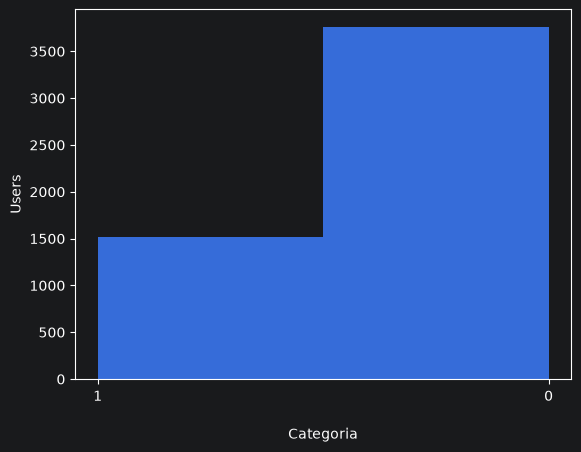

In [25]:
plt.hist(tr_y, bins=len(set(tr_y)))

plt.ylabel("Users")
plt.xlabel("Categoria")

plt.show()

# Tokenizacion

In [26]:
import nltk
from nltk.tokenize import TweetTokenizer

tokenizer = TweetTokenizer()
corpus_palabras = []
for doc in tr_txt:
    corpus_palabras += tokenizer.tokenize(doc.lower())

fdist = nltk.FreqDist(corpus_palabras)

In [27]:
len(corpus_palabras)

97473

In [28]:
def sortFreqDist(freqdict):
    aux = [(freqdict[key], key) for key in freqdict]
    aux.sort()
    aux.reverse()
    return aux  # se convierte en el diccionario

In [29]:
V = sortFreqDist(fdist)
V = V[:5000]

In [30]:
dict_indices = dict()

cont = 0
for frecuencia, word in V:
    dict_indices[word] = cont
    cont += 1

In [31]:
import numpy as np


def build_bow_tr(tr_txt, V, dict_indices):
    BOW = np.zeros((len(tr_txt), len(V)), dtype=int)

    cont_doc = 0
    for tr in tr_txt:
        fdist_doc = nltk.FreqDist(tokenizer.tokenize(tr.lower()))

        for word in fdist_doc:
            if word in dict_indices:
                BOW[cont_doc, dict_indices[word]] = 1
        cont_doc += 1

    return BOW

In [32]:
BOW_tr = build_bow_tr(tr_txt, V, dict_indices)

In [33]:
BOW_tr.shape

(5278, 5000)

In [34]:
from wordcloud import WordCloud

wordcloud = WordCloud(width=800, height=400, background_color="black").generate_from_frequencies(fdist)

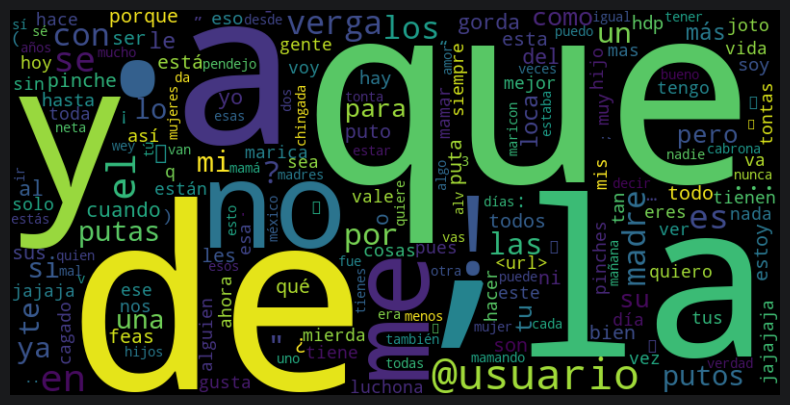

In [35]:
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation = 'bilinear')
plt.axis('off')
plt.show()

# Hacer TCOR

In [48]:
def compute_tcor(BOW):
    DTR = np.zeros((BOW.shape[1], BOW.shape[1]), dtype = int) # DTR viene de Distributional Term Representation

    for doc, i in zip(BOW, range(len(BOW))): # recorrer cada tuit en BOW
        print(doc, i)
        nonzero_positions = np.nonzero(doc)[0]
        for t1 in nonzero_positions:
            for t2 in nonzero_positions:
                DTR[t1,t2] += 1.0

    return DTR


In [49]:
TCOR_base = compute_tcor(BOW_tr)

[0 1 0 ... 0 0 0] 0
[0 0 0 ... 0 0 0] 1
[0 1 0 ... 0 0 0] 2
[0 0 0 ... 0 0 0] 3
[1 0 0 ... 0 0 0] 4
[0 0 1 ... 0 0 0] 5
[0 1 1 ... 0 0 0] 6
[0 1 0 ... 0 0 0] 7
[1 1 0 ... 0 0 0] 8
[1 0 0 ... 0 0 0] 9
[1 0 1 ... 0 0 0] 10
[1 0 1 ... 0 0 0] 11
[0 1 1 ... 0 0 0] 12
[0 0 0 ... 0 0 0] 13
[1 1 0 ... 0 0 0] 14
[0 0 1 ... 0 0 0] 15
[1 0 1 ... 0 0 0] 16
[1 1 0 ... 0 0 0] 17
[1 0 1 ... 0 0 0] 18
[0 1 1 ... 0 0 0] 19
[0 1 0 ... 0 0 0] 20
[1 0 1 ... 0 0 0] 21
[0 0 1 ... 0 0 0] 22
[0 0 0 ... 0 0 0] 23
[1 0 0 ... 0 0 0] 24
[0 0 1 ... 0 0 0] 25
[1 1 0 ... 0 0 0] 26
[0 1 0 ... 0 0 0] 27
[1 0 1 ... 0 0 0] 28
[1 0 1 ... 0 0 0] 29
[1 1 1 ... 0 0 0] 30
[0 0 0 ... 0 0 0] 31
[1 0 0 ... 0 0 0] 32
[0 0 1 ... 0 0 0] 33
[0 0 0 ... 0 0 0] 34
[0 1 1 ... 0 0 0] 35
[0 0 1 ... 0 0 0] 36
[0 1 0 ... 0 0 0] 37
[1 0 0 ... 0 0 0] 38
[1 1 1 ... 0 0 0] 39
[1 1 0 ... 0 0 0] 40
[0 0 1 ... 0 0 0] 41
[0 1 1 ... 0 0 0] 42
[0 0 0 ... 0 0 0] 43
[0 0 0 ... 0 0 0] 44
[1 0 1 ... 0 0 0] 45
[0 0 0 ... 0 0 0] 46
[1 1 0 ... 0 0 0] 47
[0

In [46]:
TCOR_base.shape

(5000, 5000)

In [47]:
TCOR_base

array([[2306, 1046,  941, ...,    0,    1,    0],
       [1046, 2354,  987, ...,    1,    1,    1],
       [ 941,  987, 2094, ...,    1,    1,    0],
       ...,
       [   0,    1,    1, ...,    1,    0,    0],
       [   1,    1,    1, ...,    0,    1,    0],
       [   0,    1,    0, ...,    0,    0,    1]], shape=(5000, 5000))

In [50]:
from sklearn import preprocessing
TCOR_base = preprocessing.normalize(TCOR_base, norm='l2')

# Feature Selection

In [51]:
from sklearn.feature_selection import SelectKBest, chi2
feats = SelectKBest(chi2, k=1000)
feats.fit(BOW_tr, tr_y)

SelectKBest(k=1000, score_func=<function chi2 at 0x00000203C1BCE770>)

In [52]:
best = feats.get_support(indices=True)

In [59]:
best

array([   1,    2,    4,    5,    6,    8,    9,   10,   11,   12,   15,
         16,   17,   22,   24,   27,   29,   31,   35,   36,   38,   39,
         41,   42,   43,   44,   46,   49,   50,   51,   52,   53,   54,
         55,   56,   57,   58,   59,   60,   61,   62,   64,   65,   66,
         67,   70,   73,   76,   79,   80,   84,   86,   87,   88,   93,
         94,   96,   97,   98,   99,  101,  104,  105,  107,  108,  110,
        111,  112,  113,  114,  116,  117,  119,  120,  122,  124,  126,
        129,  131,  132,  134,  135,  136,  137,  139,  143,  145,  153,
        155,  157,  165,  166,  167,  168,  171,  172,  173,  178,  179,
        180,  181,  183,  186,  187,  191,  193,  194,  196,  198,  201,
        202,  203,  206,  208,  209,  216,  219,  221,  222,  224,  225,
        229,  233,  236,  240,  241,  243,  244,  245,  247,  248,  250,
        253,  254,  255,  256,  258,  260,  261,  264,  265,  268,  269,
        275,  276,  277,  278,  279,  280,  281,  2

In [55]:
dict_indice_invertido = {}
for w in dict_indices:
    dict_indice_invertido[dict_indices[w]] =  w

In [58]:
dict_indice_invertido

{0: 'que',
 1: 'de',
 2: ',',
 3: '.',
 4: 'la',
 5: 'a',
 6: 'y',
 7: 'no',
 8: 'me',
 9: '!',
 10: '@usuario',
 11: 'el',
 12: 'en',
 13: 'se',
 14: 'es',
 15: 'verga',
 16: 'madre',
 17: 'los',
 18: 'con',
 19: 'por',
 20: '?',
 21: 'las',
 22: 'mi',
 23: 'un',
 24: 'te',
 25: 'ya',
 26: 'si',
 27: 'putos',
 28: 'lo',
 29: '"',
 30: 'putas',
 31: 'una',
 32: 'para',
 33: 'como',
 34: '...',
 35: 'pero',
 36: 'su',
 37: '😂',
 38: 'tu',
 39: 'loca',
 40: 'le',
 41: 'más',
 42: 'gorda',
 43: 'yo',
 44: 'del',
 45: 'al',
 46: 'cuando',
 47: 'o',
 48: 'bien',
 49: 'son',
 50: 'estoy',
 51: '¿',
 52: 'qué',
 53: 'porque',
 54: 'feas',
 55: 'ni',
 56: 'está',
 57: 'les',
 58: 'pinche',
 59: 'esta',
 60: 'puta',
 61: 'todos',
 62: ':',
 63: 'ser',
 64: 'puto',
 65: 'sus',
 66: 'todo',
 67: 'soy',
 68: 'eso',
 69: 'tan',
 70: 'hdp',
 71: 'así',
 72: 'hasta',
 73: 'muy',
 74: 'hay',
 75: '…',
 76: 'mis',
 77: 'este',
 78: 'mamar',
 79: 'quiero',
 80: 'q',
 81: 'nos',
 82: 'solo',
 83: '¡',
 8

In [56]:
target_words = [dict_indice_invertido[index] for index in best]
words = [word for word in target_words if word in dict_indices]
target_matrix = np.array([TCOR_base[dict_indices[word]] for word in words])

In [57]:
target_matrix.shape

(1000, 5000)

In [61]:
words

['de',
 ',',
 'la',
 'a',
 'y',
 'me',
 '!',
 '@usuario',
 'el',
 'en',
 'verga',
 'madre',
 'los',
 'mi',
 'te',
 'putos',
 '"',
 'una',
 'pero',
 'su',
 'tu',
 'loca',
 'más',
 'gorda',
 'yo',
 'del',
 'cuando',
 'son',
 'estoy',
 '¿',
 'qué',
 'porque',
 'feas',
 'ni',
 'está',
 'les',
 'pinche',
 'esta',
 'puta',
 'todos',
 ':',
 'puto',
 'sus',
 'todo',
 'soy',
 'hdp',
 'muy',
 'mis',
 'quiero',
 'q',
 'eres',
 'marica',
 'joto',
 'cosas',
 'vale',
 'mejor',
 'hoy',
 'esa',
 'vida',
 'tengo',
 '️',
 'pinches',
 'día',
 'ese',
 'sin',
 'mierda',
 'luchona',
 '😭',
 '-',
 '(',
 ')',
 'tienen',
 'hijo',
 '😍',
 'tus',
 'alguien',
 'tontas',
 '“',
 'mas',
 'cagado',
 '”',
 'pendejo',
 'tonta',
 'puedo',
 'hijos',
 'sí',
 'algo',
 'maricon',
 'cabrona',
 'van',
 'esos',
 'wey',
 'vas',
 'sé',
 'mucho',
 'mañana',
 'mamá',
 'alv',
 '❤',
 'veces',
 'méxico',
 ';',
 'esto',
 'años',
 'días',
 'amor',
 'tienes',
 'mundo',
 'estaba',
 'siento',
 'pendeja',
 'he',
 'digo',
 'd',
 'cuenta',
 'p

In [60]:
target_words

['de',
 ',',
 'la',
 'a',
 'y',
 'me',
 '!',
 '@usuario',
 'el',
 'en',
 'verga',
 'madre',
 'los',
 'mi',
 'te',
 'putos',
 '"',
 'una',
 'pero',
 'su',
 'tu',
 'loca',
 'más',
 'gorda',
 'yo',
 'del',
 'cuando',
 'son',
 'estoy',
 '¿',
 'qué',
 'porque',
 'feas',
 'ni',
 'está',
 'les',
 'pinche',
 'esta',
 'puta',
 'todos',
 ':',
 'puto',
 'sus',
 'todo',
 'soy',
 'hdp',
 'muy',
 'mis',
 'quiero',
 'q',
 'eres',
 'marica',
 'joto',
 'cosas',
 'vale',
 'mejor',
 'hoy',
 'esa',
 'vida',
 'tengo',
 '️',
 'pinches',
 'día',
 'ese',
 'sin',
 'mierda',
 'luchona',
 '😭',
 '-',
 '(',
 ')',
 'tienen',
 'hijo',
 '😍',
 'tus',
 'alguien',
 'tontas',
 '“',
 'mas',
 'cagado',
 '”',
 'pendejo',
 'tonta',
 'puedo',
 'hijos',
 'sí',
 'algo',
 'maricon',
 'cabrona',
 'van',
 'esos',
 'wey',
 'vas',
 'sé',
 'mucho',
 'mañana',
 'mamá',
 'alv',
 '❤',
 'veces',
 'méxico',
 ';',
 'esto',
 'años',
 'días',
 'amor',
 'tienes',
 'mundo',
 'estaba',
 'siento',
 'pendeja',
 'he',
 'digo',
 'd',
 'cuenta',
 'p

In [63]:
from tsne import tsne

reduced_matrix = tsne(target_matrix, 2)

Preprocessing the data using PCA...
Computing pairwise distances...
Computing P-values for point 0 of 1000...
Computing P-values for point 500 of 1000...
Mean value of sigma: 0.173527
Iteration 10: error is 17.965976
Iteration 20: error is 17.750376
Iteration 30: error is 17.740287
Iteration 40: error is 17.658768
Iteration 50: error is 17.700952
Iteration 60: error is 17.697772
Iteration 70: error is 17.836881
Iteration 80: error is 17.883239
Iteration 90: error is 17.936177
Iteration 100: error is 17.813402
Iteration 110: error is 2.345779
Iteration 120: error is 1.971527
Iteration 130: error is 1.851396
Iteration 140: error is 1.780582
Iteration 150: error is 1.731644
Iteration 160: error is 1.695082
Iteration 170: error is 1.665852
Iteration 180: error is 1.642623
Iteration 190: error is 1.624412
Iteration 200: error is 1.609935
Iteration 210: error is 1.597900
Iteration 220: error is 1.587800
Iteration 230: error is 1.579087
Iteration 240: error is 1.571330
Iteration 250: error is

In [64]:
reduced_matrix.shape

(1000, 2)

C:\Users\JosuePc\AppData\Local\Temp\ipykernel_34760\2777583900.py:10: UserWarning: Glyph 129315 (\N{ROLLING ON THE FLOOR LAUGHING}) missing from font(s) DejaVu Sans.
  plt.savefig("TCOR")
C:\Users\JosuePc\AppData\Local\Temp\ipykernel_34760\2777583900.py:10: UserWarning: Glyph 128148 (\N{BROKEN HEART}) missing from font(s) DejaVu Sans.
  plt.savefig("TCOR")
C:\Users\JosuePc\AppData\Local\Temp\ipykernel_34760\2777583900.py:10: UserWarning: Glyph 127814 (\N{AUBERGINE}) missing from font(s) DejaVu Sans.
  plt.savefig("TCOR")
C:\Users\JosuePc\AppData\Local\Temp\ipykernel_34760\2777583900.py:10: UserWarning: Glyph 128579 (\N{UPSIDE-DOWN FACE}) missing from font(s) DejaVu Sans.
  plt.savefig("TCOR")
C:\Users\JosuePc\AppData\Local\Temp\ipykernel_34760\2777583900.py:10: UserWarning: Glyph 128556 (\N{GRIMACING FACE}) missing from font(s) DejaVu Sans.
  plt.savefig("TCOR")
C:\Users\JosuePc\AppData\Local\Temp\ipykernel_34760\2777583900.py:10: UserWarning: Glyph 129316 (\N{DROOLING FACE}) missing f

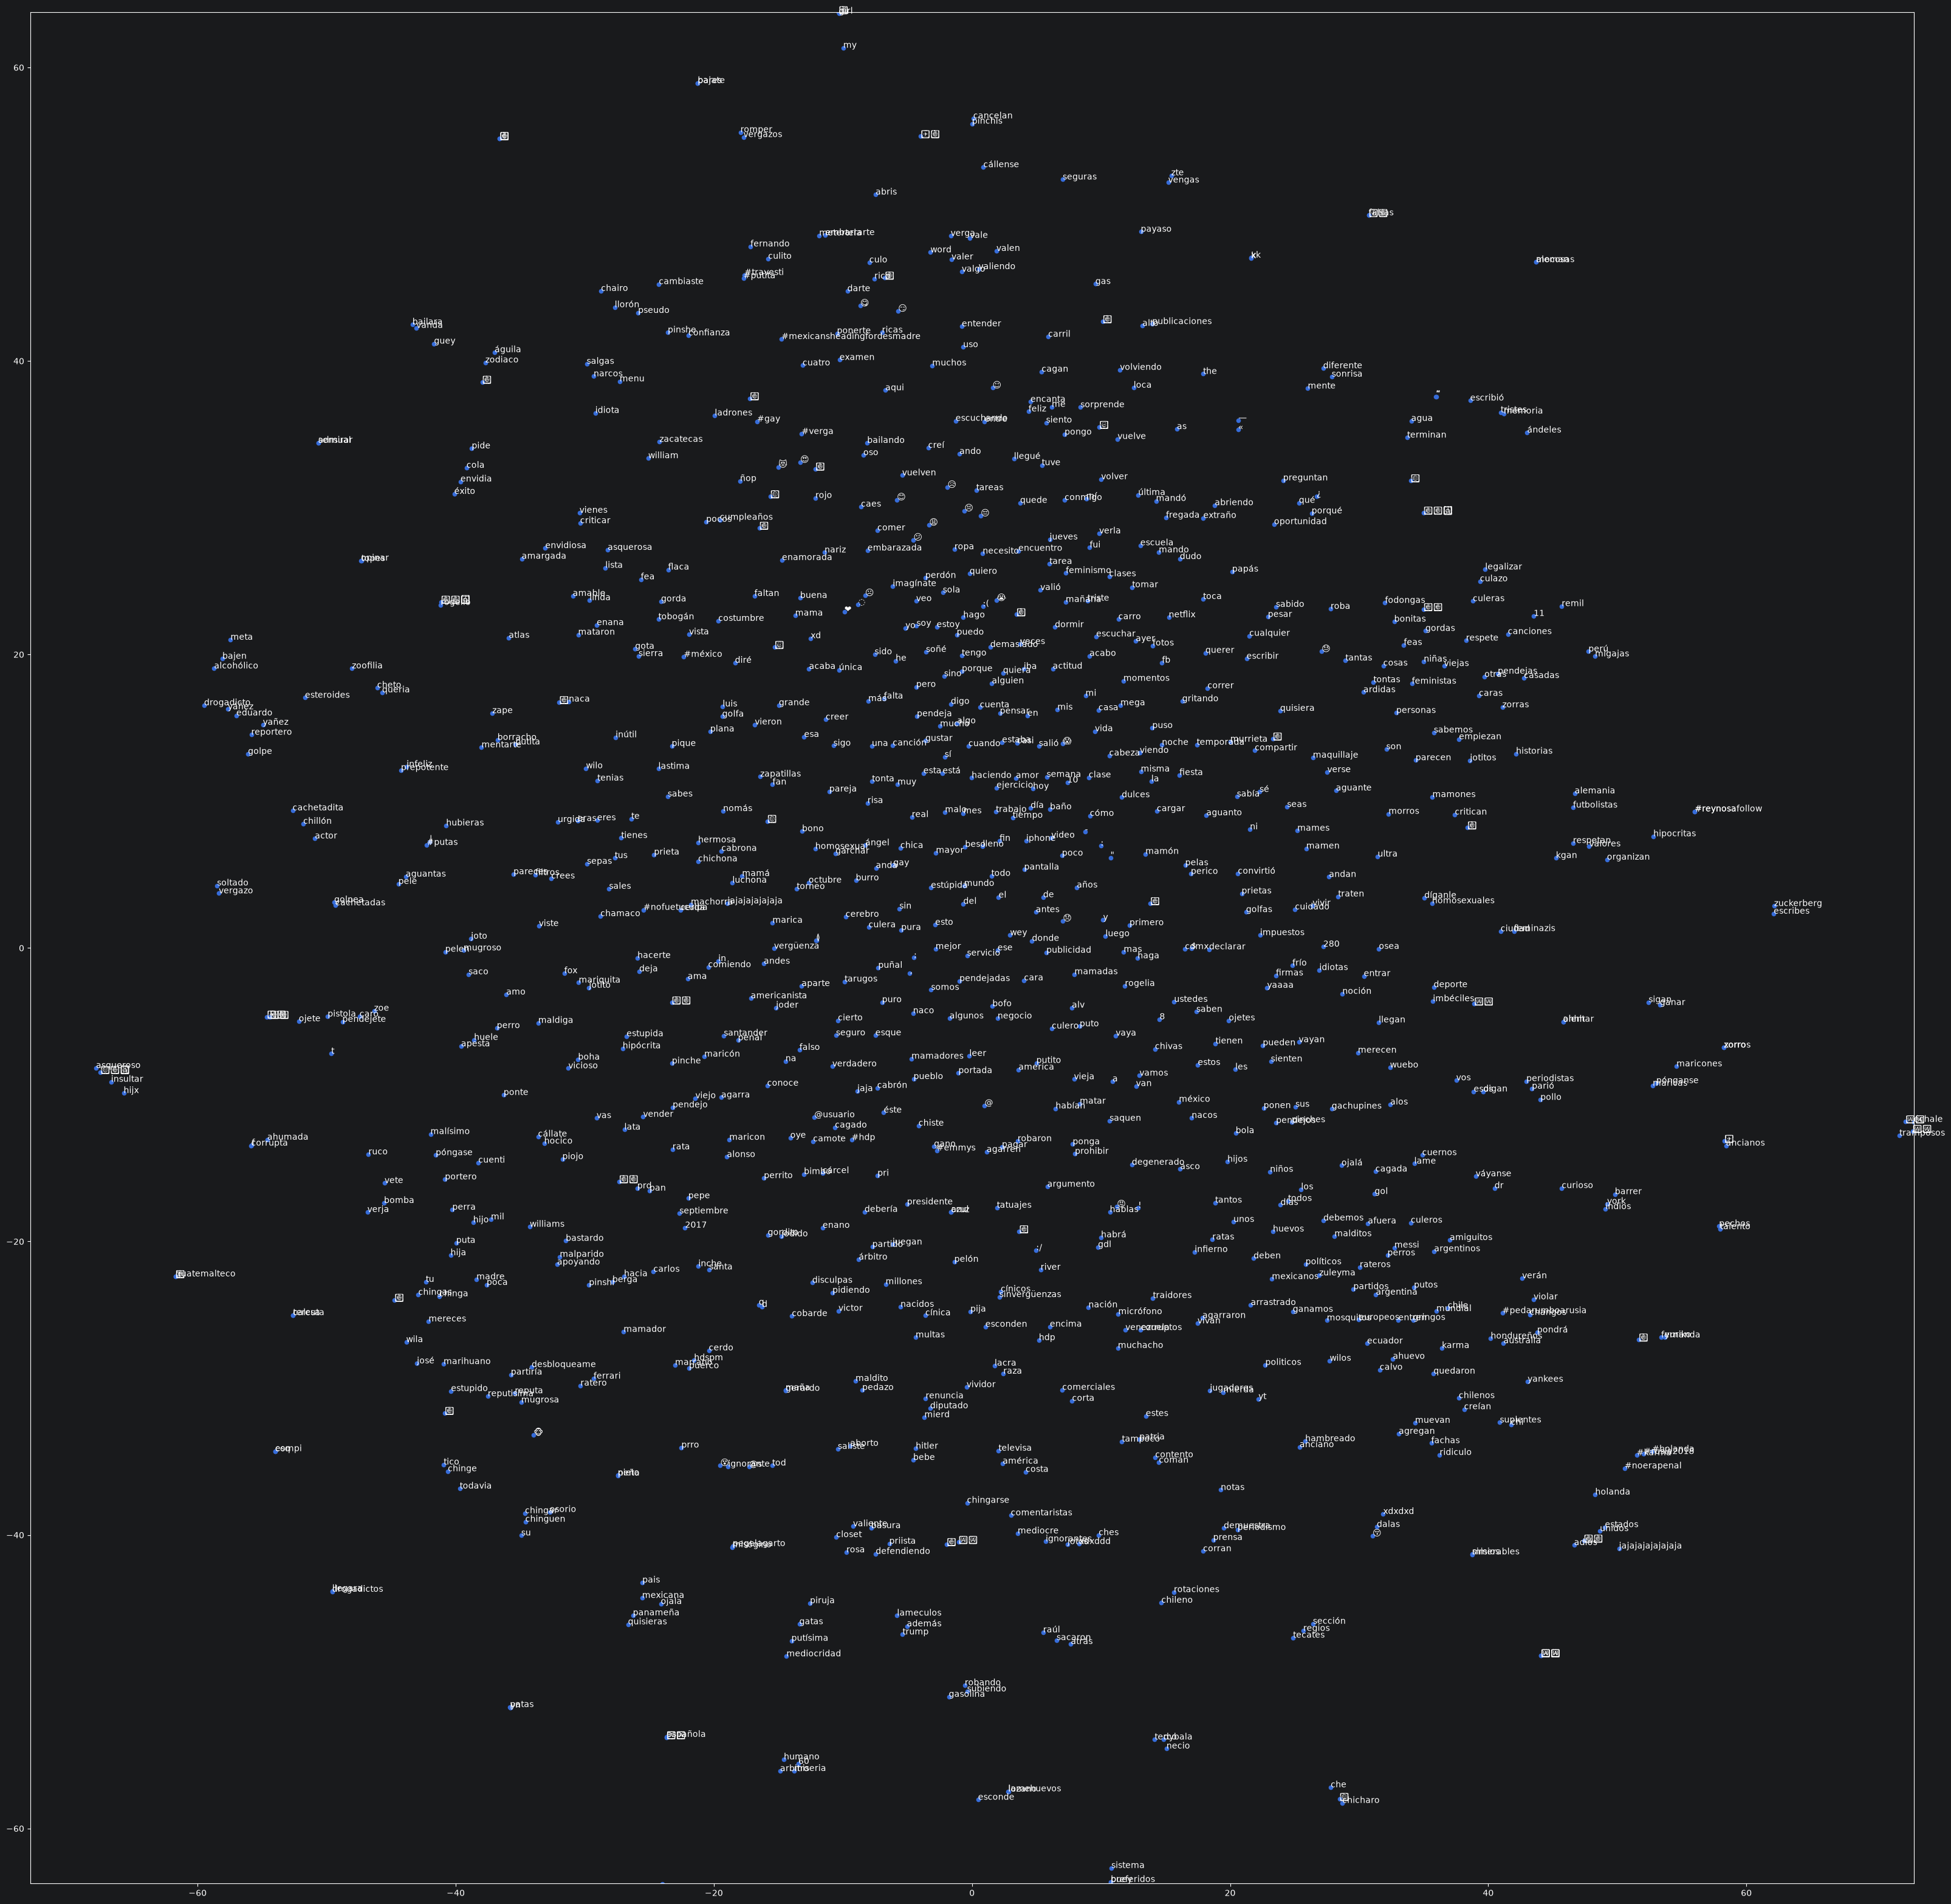

In [65]:
max_x = np.amax(reduced_matrix, axis=0)[0]
max_y = np.amax(reduced_matrix, axis=0)[1]
plt.figure(figsize=(40, 40), dpi=100); plt.xlim((-max_x,max_x)); plt.ylim((-max_y,max_y))
plt.scatter(reduced_matrix[:, 0], reduced_matrix[:, 1], 20);
for idx, word in enumerate(words[:]):
    x = reduced_matrix[idx, 0]
    y = reduced_matrix[idx, 1]
    plt.annotate(word, (x,y))

plt.savefig("TCOR")